# Data quality and provenance

## Goal

Reproduce the displayed results from distributed local inputs, without downloading data. Run every cell in order. Numerical statements are computed in the result cells; none are hard-coded.

## Setup

Use the project's Python environment. Start Jupyter inside this repository or set `ECONHACK_REPO` explicitly. The first cell runs `python -m econhack.cli verify` before reading data. The CLI checks source and processed manifests; tables and PNGs receive separate byte-hash receipts below. No acquisition functions or model `run()` entrypoints are called.

In [1]:
import hashlib
import importlib
import inspect
import io
import json
import os
from pathlib import Path
import subprocess
import sys

def find_repository():
    explicit = os.environ.get("ECONHACK_REPO")
    candidates = [Path(explicit).expanduser().resolve()] if explicit else [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        if (candidate / "src/econhack/cli.py").is_file() and (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook inside the repository, or set ECONHACK_REPO to its root.")

ROOT = find_repository()
os.environ["ECONHACK_OFFLINE"] = "1"
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path.insert(0, str(ROOT / "src"))
environment = os.environ.copy()
environment["PYTHONPATH"] = str(ROOT / "src") + os.pathsep + environment.get("PYTHONPATH", "")
verification = subprocess.run(
    [sys.executable, "-m", "econhack.cli", "verify"], cwd=ROOT, env=environment,
    capture_output=True, text=True, check=True,
)
print(verification.stdout.strip())
print(f"Repository: {ROOT.name}\nPython: {sys.version.split()[0]}\nMode: local files only")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Code, Image, Markdown, display

pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 30)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=["#176b87", "#b85c38"])})
PROCESSED = ROOT / "data/processed"
TABLES = ROOT / "outputs/tables"
FIGURES = ROOT / "outputs/figures"
input_receipts = []
processed_manifest = json.loads((ROOT / "data/processed_manifest.json").read_text())

def local_file(relative):
    path = (ROOT / relative).resolve()
    if ROOT not in path.parents or not path.is_file():
        raise FileNotFoundError(f"Required local input missing: {relative}. Run the project pipeline and snapshot first.")
    return path

def receipt(path):
    relative = str(path.relative_to(ROOT))
    input_receipts.append({"path": relative, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})

def read_csv(relative, **kwargs):
    path = local_file(relative)
    if str(path.relative_to(ROOT)).startswith("data/processed/") and str(path.relative_to(ROOT)) not in processed_manifest:
        raise ValueError(f"Processed input is not in the verified manifest: {relative}. Run cli snapshot first.")
    receipt(path)
    return pd.read_csv(path, **kwargs)

def read_json(relative):
    path = local_file(relative)
    receipt(path)
    return json.loads(path.read_text())

def show_png(name, required=True):
    path = FIGURES / f"{name}.png"
    if not path.is_file() and not required:
        display(Markdown(f"Figure `{name}.png` was not produced; consult the model status and estimability table."))
        return
    path = local_file(str(path.relative_to(ROOT)))
    receipt(path)
    display(Image(data=path.read_bytes(), format="png", embed=True, width=1000))

def show_figure(figure):
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
    display(Image(data=buffer.getvalue(), format="png", embed=True, width=1000))

def show_source(module_name, names):
    module = importlib.import_module(module_name)
    display(Markdown(f"Source: `src/{module_name.replace('.', '/')}.py`. Functions below are displayed, not invoked."))
    for name in names:
        display(Code(inspect.getsource(getattr(module, name)), language="python"))

def show_status(name):
    statuses = read_json("outputs/model_status.json")
    display(pd.DataFrame([{key: value for key, value in statuses.get(name, {"status": "not_run"}).items()
                           if key in {"status", "reason", "n", "updated_utc", "formula", "input_mode"}}]))

Verified 38 source/extract hashes; 0 large source files omitted from distribution.
Repository: econhackathon2026
Python: 3.13.7
Mode: local files only


## Context and methods

Inspect manifest coverage, source lineage, model status, and missingness. A successful integrity check establishes byte consistency, not substantive validity. Missing large raw files may be allowed by the distribution policy; missing or altered processed files are not.

### Source inventory

In [2]:
raw_manifest = read_json("data/manifest.json")
source_rows = [{"path": path, "source": entry.get("source"), "url": entry.get("url"),
                "bytes": entry.get("bytes"), "distributed": (ROOT / path).is_file()}
               for path, entry in raw_manifest.items()]
display(pd.DataFrame(source_rows))
statuses = read_json("outputs/model_status.json")
display(pd.DataFrame([{"model": name, "status": entry.get("status"), "reason": entry.get("reason")}
                      for name, entry in statuses.items()]))

,path,source,url,bytes,distributed
0,data/raw/acs/acsdt5y2023-b01003.dat,Census ACS 2019–2023 five-year table-based sum...,https://www2.census.gov/programs-surveys/acs/s...,18311997,True
1,data/raw/acs/acsdt5y2023-b19013.dat,Census ACS 2019–2023 five-year table-based sum...,https://www2.census.gov/programs-surveys/acs/s...,17884943,True
2,data/raw/acs/acsdt5y2023-b17001.dat,Census ACS 2019–2023 five-year table-based sum...,https://www2.census.gov/programs-surveys/acs/s...,118402375,True
3,data/raw/acs/acsdt5y2023-b01001.dat,Census ACS 2019–2023 five-year table-based sum...,https://www2.census.gov/programs-surveys/acs/s...,200088223,True
4,data/raw/nyc/gazetteer2023_ny_tracts.txt,Census 2023 NY tract Gazetteer,https://www2.census.gov/geo/docs/maps-data/dat...,1087802,True
5,data/raw/nyc/facilities.json,NYC DCP Facilities Database ji82-xba5 live sna...,https://data.cityofnewyork.us/resource/ji82-xb...,32244163,True
6,data/raw/cdc/ny_loneliness_2025.json,"CDC PLACES 2025 release, tract long format cws...",https://data.cdc.gov/resource/cwsq-ngmh.json?%...,3302210,True
7,data/raw/nyc/libraries.geojson,NYC Open Data libraries feuq-due4,https://data.cityofnewyork.us/api/v3/views/feu...,113457,True
8,data/raw/nyc/park_acquisitions.geojson,NYC Open Data park_acquisitions enfh-gkve,https://data.cityofnewyork.us/api/v3/views/enf...,8232421,True
9,data/raw/panel/bfs_county_apps_annual.xlsx,BFS annual county applications,https://www.census.gov/econ/bfs/xlsx/bfs_count...,525938,True


,model,status,reason
0,nyc_equity,estimated,Exploratory tract association; HC3 intervals d...
1,access_loneliness,estimated_exploratory,2023 CDC modeled outcome vs current facilities...
2,library_did,not_estimated,"No verified branch-level treatment dates, matc..."
3,atus,incomplete_microdata,Official multi-year archive unavailable; age 1...
4,nyc_supplements,downloaded_audited,Library GIS and Parks acquisition geometries d...
5,panel,complete,"NY 62 counties, 2018–2023: 372/372 usable curr..."
6,third_place_index,downloaded_not_redistributed,Compiled index redistribution permission unres...
7,atus_published,complete_published_only,Official published all-15+ socializing/communi...


### Processed coverage and missing values

In [3]:
grain = {"nyc_access": ["geoid"], "nyc_loneliness": ["geoid"],
         "nyc_selected_facilities": ["site_key"], "cdc_ny_loneliness": ["geoid"],
         "panel_county_year": ["county_fips", "year"],
         "atus_socializing_annual": ["year", "age_group"], "atus_published_annual": ["year"]}
profiles = []
for relative in sorted(processed_manifest):
    if not relative.endswith(".csv"):
        continue
    frame = read_csv(relative)
    keys = grain.get(Path(relative).stem, ["GEO_ID"] if "GEO_ID" in frame else [])
    profiles.append({"dataset": Path(relative).stem, "rows": len(frame), "columns": len(frame.columns),
                     "key": ", ".join(keys) or "see data dictionary",
                     "duplicate_keys": int(frame.duplicated(keys).sum()) if keys else np.nan,
                     "missing_cells_pct": 100 * frame.isna().to_numpy().mean() if frame.size else np.nan})
profile_table = pd.DataFrame(profiles)
display(profile_table)
print("Duplicate site keys among invalid-coordinate facility records need separate interpretation; see facility_selection QA.")

,dataset,rows,columns,key,duplicate_keys,missing_cells_pct
0,acs2023_nyc_b01001,2327,45,GEO_ID,0.0,0.0000
1,acs2023_nyc_b01003,2327,3,GEO_ID,0.0,0.0000
2,acs2023_nyc_b17001,2327,5,GEO_ID,0.0,0.0000
3,acs2023_nyc_b19013,2327,3,GEO_ID,0.0,0.0000
4,atus_published_annual,22,14,year,0.0,7.7922
5,cdc_ny_loneliness,5289,24,geoid,0.0,0.0000
6,nyc_access,2327,72,geoid,0.0,0.4864
7,nyc_loneliness,2190,76,geoid,0.0,0.0078
8,nyc_selected_facilities,1541,43,site_key,1.0,3.9358
9,panel_acquisition,13,7,see data dictionary,NaN,15.3846


Duplicate site keys among invalid-coordinate facility records need separate interpretation; see facility_selection QA.


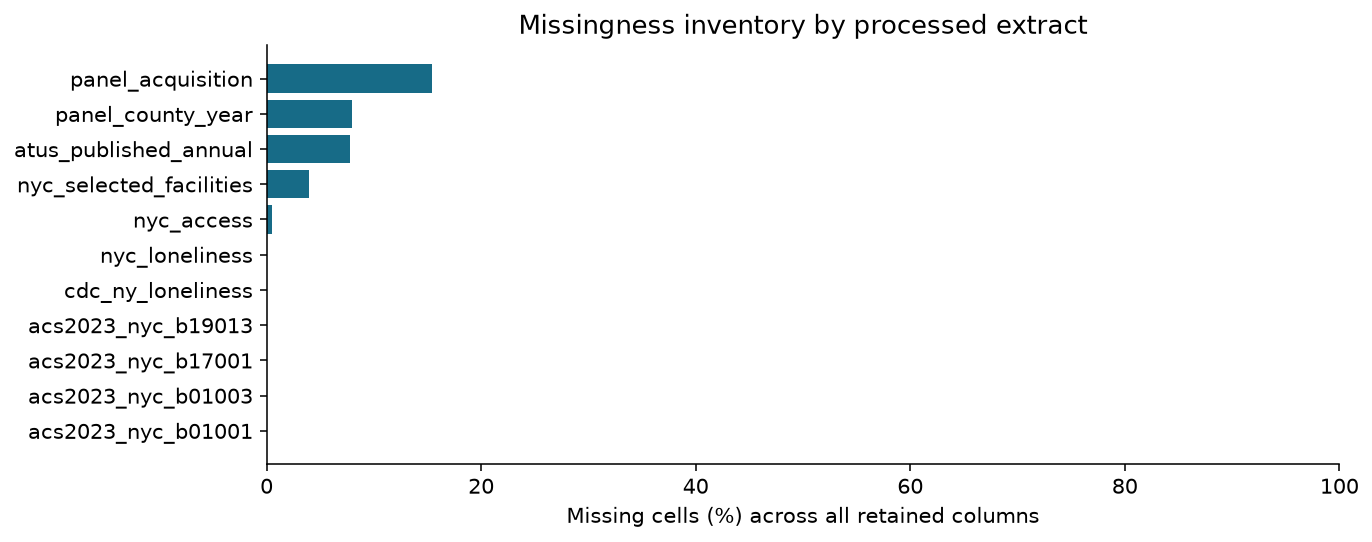

In [4]:
if not profile_table.empty:
    visible = profile_table.sort_values("missing_cells_pct", ascending=True)
    figure, axis = plt.subplots(figsize=(10, max(4, 0.35 * len(visible))))
    axis.barh(visible.dataset, visible.missing_cells_pct, color="#176b87")
    axis.set(xlabel="Missing cells (%) across all retained columns", title="Missingness inventory by processed extract", xlim=(0, 100))
    figure.tight_layout()
    show_figure(figure)
    plt.close(figure)

### Recorded QA summaries

In [5]:
summaries = []
for path in sorted((ROOT / "outputs/qa").glob("*.json")):
    report = read_json(str(path.relative_to(ROOT)))
    if isinstance(report, dict):
        summaries.append({"check": path.stem, **{key: value for key, value in report.items()
                           if isinstance(value, (int, float, str, bool)) or value is None}})
display(pd.DataFrame(summaries))

,check,n,r_squared,condition_number,covariance,design_rank,design_columns,breusch_pagan_p,...,tests,failures,errors,figures_png,figures_svg,tracked_files,restricted_files_tracked,local_documentation_links
0,access_loneliness_diagnostics,2190.0,0.6333,1508.4651,HC3,11.0,11.0,2.3357e-31,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,access_loneliness_spatial,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,acs_nyc,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,facdb_raw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,facility_selection,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,gazetteer_nyc,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,libraries_schema,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,loneliness_attrition,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,nyc_access,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,nyc_equity_attrition,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Interpretation and limits

Inspect incomplete model statuses before using results. Coverage, source vintage, units, suppression, and ecological interpretation remain substantive checks even when hashes agree. Missing cells can be intentional, especially ATUS 2020, first-year lags, and unreported inference; they are never filled with invented zeros.

## Inputs used

Exact local inputs and SHA-256 hashes for this execution. These receipts identify table/figure versions; they are not an independent validation of their statistical content.

In [6]:
display(pd.DataFrame(input_receipts).drop_duplicates().reset_index(drop=True))

,path,sha256
0,data/manifest.json,f172e6266d43a050a45f0011bd6d6ba94fc692303fba1f...
1,outputs/model_status.json,3325cedafcf9fe7d8ff7bab928673fdb271f379ac69b9c...
2,data/processed/acs2023_nyc_b01001.csv,5e59389cac0fa2219a4ba807e73a331f03fd9a7f13e932...
3,data/processed/acs2023_nyc_b01003.csv,2dd7889b98ea495045f1ff2bd774e4bbd62ba8bb5b2c3b...
4,data/processed/acs2023_nyc_b17001.csv,59829321f9a7ad4d8135c8bac08128dd03ac1ca8802e9b...
5,data/processed/acs2023_nyc_b19013.csv,c4ac28770575c9f777cc044ad4b1f40ce84c2ee955487e...
6,data/processed/atus_published_annual.csv,85c3e8148fe4c8fd30f9f6dcc16bdfa3907701250ce717...
7,data/processed/cdc_ny_loneliness.csv,6a7ab120b39fcc346d50a4f12d34814be77c538f0fc4b7...
8,data/processed/nyc_access.csv,dc4074b06a30882187ea6e042d7b4499e978d9dfe8259f...
9,data/processed/nyc_loneliness.csv,6928c802abb6c832ac8bff646d3313261b7010d30831bc...
